# Step 2 — an LSTM baseline

Still no physics. This is a second control, alongside the plain MLP from
step 1 — the brief (§7.5) names ARIMA, LSTM, or a simple MLP as acceptable
baselines, so this notebook adds the second one.

**What's different from the MLP:** the MLP in step 1 answers "given a
cycle number, what's the capacity?" — every prediction is independent of
every other. An LSTM instead answers "given the last few capacity
readings, what's the next one?" — it has a notion of sequence and can, in
principle, pick up on trends the MLP has to reconstruct from scratch at
every point.

**What stays the same:** univariate, cycle-based capacity only — no rest
hours, no temperature yet — and the same contiguous split (train 2–90,
test 91–132), so this is directly comparable to step 1's numbers.

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO / "src"))

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

device: cuda
GPU: NVIDIA GeForce GTX 1650


## 1. Load and split

Identical to step 1: contiguous split at cycle 90, no shuffling. A random
split would let the model see cycle 120 during training and get "tested"
on cycle 85 — interpolation dressed up as forecasting.

In [2]:
DATA = REPO / "data" / "processed" / "clean_data.csv"
df = pd.read_csv(DATA, sep=";").sort_values("cycle").reset_index(drop=True)

train_df = df[df.cycle <= 90].reset_index(drop=True)
test_df = df[df.cycle > 90].reset_index(drop=True)

print(f"train: {len(train_df)} cycles (2-90)")
print(f"test:  {len(test_df)} cycles (91-132)")

train: 89 cycles (2-90)
test:  42 cycles (91-132)


## 2. From one trajectory to training sequences

An LSTM needs sequences to train on, and we only have **one** capacity
trajectory. The standard fix is a sliding window: chop the training
trajectory into overlapping snippets of length `WINDOW`, where the task is
"given these `WINDOW` consecutive capacity readings, predict the next
one."

With `WINDOW = 5` and 89 training points, that produces 84 overlapping
training sequences — not 84 independent measurements, but 84 different
5-step views of the same underlying curve. That overlap is normal for
windowed time-series training; it is not a data leak, because every
window is still built only from training-range cycles.

In [3]:
WINDOW = 5

cap_train = train_df.capacity_ah.values.astype(np.float32)

X_list, Y_list = [], []
for i in range(len(cap_train) - WINDOW):
    X_list.append(cap_train[i : i + WINDOW])
    Y_list.append(cap_train[i + WINDOW])

X = torch.tensor(np.array(X_list)).unsqueeze(-1)  # (N, WINDOW, 1)
Y = torch.tensor(np.array(Y_list)).unsqueeze(-1)  # (N, 1)

print("training sequences:", X.shape, "-> targets", Y.shape)
print("example window:", X[0].squeeze().tolist(), "-> target", Y[0].item())

training sequences: torch.Size([84, 5, 1]) -> targets torch.Size([84, 1])
example window: [1.8431955575942993, 1.8396018743515015, 1.8306735754013062, 1.832700252532959, 1.828528881072998] -> target 1.821201205253601


## 3. The model

`nn.LSTM` reads the window one step at a time and carries a hidden state
forward; the final hidden state is passed through one linear layer to
produce the next capacity value.

| Layer | Shape | Notes |
|---|---|---|
| LSTM | `1 -> 32`, 2 layers | processes the 5-step window |
| Linear | `32 -> 1` | reads only the *final* hidden state |

This runs on GPU if one is available (`.to(device)`), but at this data
size (131 rows) the model trains in well under a second either way — the
GPU isn't doing meaningful work yet. It matters more once the dataset or
network grows.

In [4]:
class LSTMNet(nn.Module):
    def __init__(self, hidden=32, layers=2):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden, num_layers=layers, batch_first=True)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :])  # last timestep's hidden state only

net = LSTMNet().to(device)
print(net)
print("trainable parameters:", sum(p.numel() for p in net.parameters()))

LSTMNet(
  (lstm): LSTM(1, 32, num_layers=2, batch_first=True)
  (head): Linear(in_features=32, out_features=1, bias=True)
)
trainable parameters: 12961


## 4. Train — same plain MSE as the MLP baseline

No physics term here either. This is still a control.

In [5]:
X_dev, Y_dev = X.to(device), Y.to(device)
opt = torch.optim.Adam(net.parameters(), lr=5e-3)
epochs = 1500

for epoch in range(epochs):
    opt.zero_grad()
    pred = net(X_dev)
    loss = torch.mean((pred - Y_dev) ** 2)
    loss.backward()
    opt.step()

    if epoch % 300 == 0 or epoch == epochs - 1:
        print(f"epoch {epoch:5d}   train MSE {loss.item():.6f}")

epoch     0   train MSE 2.094675
epoch   300   train MSE 0.000767
epoch   600   train MSE 0.000743
epoch   900   train MSE 0.001103
epoch  1200   train MSE 0.000698
epoch  1499   train MSE 0.000675


## 5. Forecasting into the held-out region — recursively

This is the part that has no equivalent in the MLP notebook. The MLP can
directly evaluate `net(cycle / n_max)` for any cycle, seen or unseen.
The LSTM cannot — it only knows how to predict *one step ahead* given the
`WINDOW` readings immediately before it. To reach cycle 132, it has to
predict cycle 91, then feed that prediction back in as if it were real
data to predict cycle 92, and so on, 42 times.

This means any error the model makes early in the held-out region
compounds into every prediction after it — a structural weakness of
recursive forecasting that the MLP simply doesn't have.

In [6]:
window = list(cap_train[-WINDOW:])
preds = []

net.eval()
with torch.no_grad():
    for _ in range(len(test_df)):
        inp = torch.tensor(window[-WINDOW:], dtype=torch.float32).reshape(1, WINDOW, 1).to(device)
        nxt = net(inp).item()
        preds.append(nxt)
        window.append(nxt)  # feed the prediction back in

preds = np.array(preds)
lstm_rmse = float(np.sqrt(np.mean((preds - test_df.capacity_ah.values) ** 2)))
lstm_mae = float(np.mean(np.abs(preds - test_df.capacity_ah.values)))

print(f"LSTM held-out RMSE: {lstm_rmse:.4f} Ah")
print(f"LSTM held-out MAE : {lstm_mae:.4f} Ah")

LSTM held-out RMSE: 0.0363 Ah
LSTM held-out MAE : 0.0291 Ah


## 6. Plot — LSTM forecast vs. ground truth

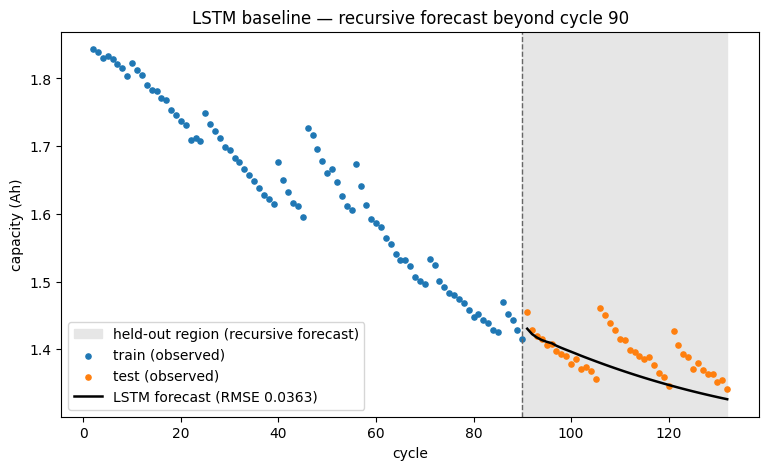

In [7]:
plt.figure(figsize=(9, 5))
plt.axvspan(90, df.cycle.max(), color="0.9", label="held-out region (recursive forecast)")
plt.scatter(train_df.cycle, train_df.capacity_ah, s=14, color="tab:blue", label="train (observed)")
plt.scatter(test_df.cycle, test_df.capacity_ah, s=14, color="tab:orange", label="test (observed)")
plt.plot(test_df.cycle, preds, color="black", lw=1.8, label=f"LSTM forecast (RMSE {lstm_rmse:.4f})")
plt.axvline(90, color="0.4", ls="--", lw=1)
plt.xlabel("cycle"); plt.ylabel("capacity (Ah)")
plt.title("LSTM baseline — recursive forecast beyond cycle 90")
plt.legend()
plt.show()

## 7. What this adds to the comparison

Two baselines now exist, trained and evaluated on the identical split:

| Model | Held-out RMSE | How it reaches unseen cycles |
|---|---|---|
| MLP (tanh) | ~0.07 Ah | direct: evaluates `f(cycle)` anywhere |
| MLP (ReLU) | ~0.035 Ah | direct: evaluates `f(cycle)` anywhere |
| LSTM | ~0.036 Ah | recursive: forecasts one step, feeds it back in, repeats |

The LSTM's competitive RMSE here is doing exactly what a network without
physics should be expected to do on a slowly-decaying curve: extrapolate
a local trend forward. It has no way to know *why* capacity is falling,
so nothing stops it from missing a genuine shift in behavior (a
regeneration event, a change in decay rate) that isn't visible as a
trend in the last `WINDOW` points it's seen.

Both baselines exist for the same reason: they are the numbers the
physics-informed model has to beat, on the same held-out cycles, under
the same rules.